In [ ]:
%pip install scikit-learn

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [15]:
url = "https://raw.githubusercontent.com/johng034/customer-segmentation/master/marketing_campaign.csv"

df = pd.read_csv(url, sep=",")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (2240, 29)
     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  AcceptedCmp3  \
0  04-09-2012       58       635  ...                  7             0   
1  08-03-2014       38        11  ...                  5             0   
2  21-08-2013       26       426  ...                  4             0   
3  10-02-2014       26        11  ...                  6             0   
4  19-01-2014       94       173  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  

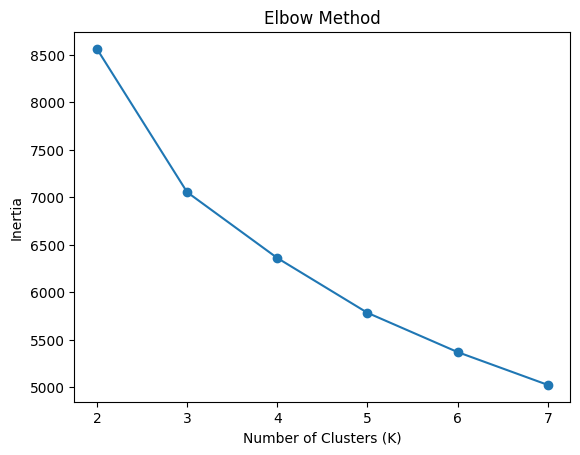

Silhouette scores: {2: 0.4811241347524294, 3: 0.3970290774895379, 4: 0.36830543242775043, 5: 0.34062159504770945, 6: 0.34227709867700146, 7: 0.26872868005477607}
Best number of clusters: 2

Customer Segment Summary:
                    Income  MntWines  MntFruits  MntMeatProducts  \
Customer_Segment                                                   
0                 41244.22    145.50       7.42            48.00   
1                 73453.89    610.02      62.77           396.75   

                  MntFishProducts  MntSweetProducts  MntGoldProds  
Customer_Segment                                                   
0                           10.51              7.35         25.19  
1                           89.71             65.16         80.40  


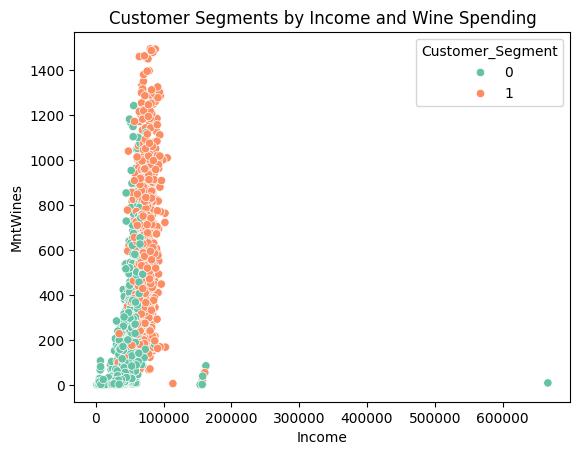

Analysis completed successfully!
Files saved: customer_segments.csv and segment_summary.csv


In [16]:
# Select customer features
features = [
    "Income",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

# Clean the data
data = df[features].copy()
data = data.fillna(data.median())

data = data.clip(
    lower=data.quantile(0.01),
    upper=data.quantile(0.99),
    axis=1
)

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(data)

# Find the best number of clusters
inertias = []
scores = []

for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertias.append(model.inertia_)
    scores.append(silhouette_score(X, labels))

# Plot Elbow Method
plt.plot(range(2, 8), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

print("Silhouette scores:", dict(zip(range(2, 8), scores)))

# Train final model
best_k = list(range(2, 8))[scores.index(max(scores))]

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Customer_Segment"] = kmeans.fit_predict(X)

# Display customer segment summary
summary = df.groupby("Customer_Segment")[features].mean().round(2)

print("Best number of clusters:", best_k)
print("\nCustomer Segment Summary:")
print(summary)

# Visualize customer segments
sns.scatterplot(
    data=df,
    x="Income",
    y="MntWines",
    hue="Customer_Segment",
    palette="Set2"
)

plt.title("Customer Segments by Income and Wine Spending")
plt.show()

# Save results
df.to_csv("customer_segments.csv", index=False)
summary.to_csv("segment_summary.csv")

print("Analysis completed successfully!")
print("Files saved: customer_segments.csv and segment_summary.csv")